# 04: RQ1 coverage, rank bins and the cross-field split

RQ1 asks where similarity search loses the papers authors credit. For every credited (question, paper) pair we look up the rank the retriever gave that paper and put it in one of three bins:

- **1 to 20:** found (counts toward Recall@20).
- **21 to 100:** on the shortlist but too low. A reranker (RQ2) can move it up.
- **beyond 100:** never reached the shortlist. Only a better retriever (RQ3) can help, because $\text{Recall@20}_{\text{final}} \le \text{Recall@100}_{\text{retriever}}$.

We then split credited papers into **in-field** (same field as the project's source paper, `queries.paper_domain`) and **cross-field** (different field), and compare recall in each.

**Which ranking.** The plan is condition B (Qwen3-Embedding-4B). Its shortlist `results/shortlist_B.parquet` is not committed yet (H100 queue item 1), so this notebook falls back to condition A (BM25, `results/run_A.parquet`). Every number below is for BM25. Rerunning the notebook after the shortlist lands switches it to B with no code change (`configs/rq1.yaml`).

Code: `src/insight/diagnose.py`. Tests: `tests/test_diagnose.py`.

In [1]:
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from insight import data, diagnose as D
pd.set_option("display.precision", 4)
cfg_raw = yaml.safe_load(open(data.ROOT / "configs" / "rq1.yaml"))
fcfg = D.FieldConfig.from_yaml(data.ROOT / "configs" / "rq1.yaml")
run_path = data.ROOT / cfg_raw["run"]
if not run_path.exists():
    print(f"{cfg_raw['run']} not found, falling back to {cfg_raw['fallback_run']}")
    run_path = data.ROOT / cfg_raw["fallback_run"]
RUN_NAME = "B (dense)" if "shortlist_B" in run_path.name else "A (BM25)"
run = pd.read_parquet(run_path)
ds = data.load()
table = ds.table
pairs = D.credited_ranks(run, table)
print("ranking:", RUN_NAME, "|", run.query_id.nunique(), "questions, up to", run.groupby("query_id").size().max(), "papers each")
print("credited pairs:", len(pairs), pairs.kind.value_counts().to_dict())

results/shortlist_B.parquet not found, falling back to results/run_A.parquet


ranking: A (BM25) | 894 questions, up to 100 papers each
credited pairs: 4845 {'subfield': 4184, 'core': 661}


## 1. Coverage ceiling

Recall@100 per question, averaged: the most any reranker on top of this shortlist could reach for Recall@20 if it put every reachable credited paper into its top 20 (and the top 20 had room).

In [2]:
pairs["all"] = "all"
cov = D.recall_by_group(pairs, "all", ks=(5, 20, 100)).droplevel(1)
cov

,n_questions,n_pairs,recall@5,recall@20,recall@100
kind,,,,,
core,207,661,0.1225,0.2406,0.4171
subfield,687,4184,0.1270,0.2853,0.4876


## 2. Rank bins

Shares of credited (question, paper) pairs in each bin. These are pooled over pairs, so questions with many credited papers weigh more; the per-question means are in the table above.

In [3]:
shares = D.bin_shares(pairs, by=["kind"])
shares

rank,1 to 20,21 to 100,beyond 100,n
kind,,,,
core,0.2315,0.1649,0.6036,661
subfield,0.2811,0.2036,0.5153,4184


## 3. Category mapping for the cross-field split

The paper reports that 49.5% of credited papers come from outside the project's subject area, and its domain tables (Tables 8 and 9 of arXiv:2610.02202) use arXiv primary categories such as `cs.LG`. It does not state how it handled Semantic Scholar and OpenAlex papers, whose "categories" are field names (`Computer Science`, `Medicine`) or concepts (`Reinforcement learning`).

Default (`configs/rq1.yaml`, logged as NEEDS REVIEW): compare full arXiv primary categories; a paper without an arXiv code is **unknown** and left out of the split. Below: how many credited pairs that leaves out, and how the cross-field share moves under the alternatives.

In [4]:
print("source domains are all arXiv codes:", ds.queries.paper_domain.map(lambda c: D.paper_field(c) is not None).all())
cat = ds.corpus.set_index("id").primary_category.reindex(pairs.doc_id)
print("credited pairs whose paper has no arXiv code:", int(cat.map(lambda c: D.paper_field(c) is None).sum()), "of", len(pairs))

variants = {
    "primary, exclude unknown (default)": D.FieldConfig(level="primary", unknown_policy="exclude"),
    "primary, unknown counts as cross": D.FieldConfig(level="primary", unknown_policy="cross"),
    "archive, exclude unknown": D.FieldConfig(level="archive", unknown_policy="exclude", name_map=fcfg.name_map),
    "archive, unknown counts as cross": D.FieldConfig(level="archive", unknown_policy="cross", name_map=fcfg.name_map),
}
rows = {}
for name, c in variants.items():
    f = D.add_fields(pairs, ds.corpus, ds.queries, c)
    row = {}
    for kind in ["core", "subfield", "all"]:
        sub = f if kind == "all" else f[f.kind == kind]
        known = sub[sub.split != "unknown"]
        row[f"cross share {kind}"] = (known.split == "cross-field").mean()
    uniq = f.drop_duplicates(["project", "doc_id"])
    known = uniq[uniq.split != "unknown"]
    row["cross share unique (project, paper)"] = (known.split == "cross-field").mean()
    row["unknown pairs"] = int((f.split == "unknown").sum())
    rows[name] = row
pd.DataFrame(rows).T

source domains are all arXiv codes: True
credited pairs whose paper has no arXiv code: 341 of 4845


,cross share core,cross share subfield,cross share all,"cross share unique (project, paper)",unknown pairs
"primary, exclude unknown (default)",0.4702,0.4590,0.4605,0.4656,341.0
"primary, unknown counts as cross",0.5159,0.4957,0.4985,0.5030,0.0
"archive, exclude unknown",0.0556,0.0406,0.0426,0.0429,179.0
"archive, unknown counts as cross",0.0998,0.0746,0.0780,0.0782,0.0


The "unique (project, paper)" column counts each credited paper once per project, since subfield questions often repeat their core question's credited papers. We do not know which counting the paper's 49.5% uses, so the table shows several. At the primary-category level the cross-field share is 0.46 to 0.47 when unknown papers are left out and 0.50 to 0.52 when they count as cross-field, which brackets the published 49.5%. At the archive level (all of `cs` is one field) it falls below 0.10, because nearly every credited paper and every source paper is in `cs`. So the published figure is consistent with a primary-category comparison, and "cross-field" in this project means "different arXiv primary category", mostly neighbouring `cs` subfields (for example `cs.CV` credited for a `cs.LG` project), not different sciences.

From here on the default mapping is used.

In [5]:
fp = D.add_fields(pairs, ds.corpus, ds.queries, fcfg)
by_field = D.recall_by_group(fp, "split", ks=(20, 100))
by_field

n_questions  n_pairs  recall@20  recall@100
kind     split                                                   
core     cross-field          144      284     0.2500      0.4286
         in-field             153      320     0.2519      0.4458
         unknown               40       57     0.2508      0.3258
subfield cross-field          522     1790     0.2579      0.4514
         in-field             553     2110     0.3048      0.5056
         unknown              181      284     0.2328      0.4459

## 4. Rank bins by field

Same pooled shares as section 2, now split by in-field, cross-field and unknown.

In [6]:
shares_f = D.bin_shares(fp, by=["kind", "split"])
shares_f

rank                  1 to 20  21 to 100  beyond 100     n
kind     split                                            
core     cross-field   0.2324     0.1549      0.6127   284
         in-field      0.2344     0.1875      0.5781   320
         unknown       0.2105     0.0877      0.7018    57
subfield cross-field   0.2615     0.2006      0.5380  1790
         in-field      0.2991     0.2071      0.4938  2110
         unknown       0.2711     0.1972      0.5317   284

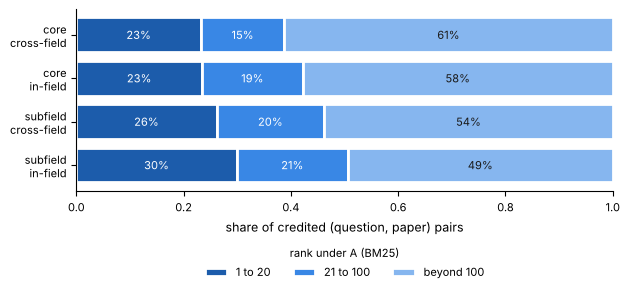

In [7]:
colors = {"1 to 20": "#1c5cab", "21 to 100": "#3987e5", "beyond 100": "#86b6ef"}
s = shares_f.drop(columns="n")
s = s[[i[1] != "unknown" for i in s.index]]
labels = [f"{k}\n{sp}" for k, sp in s.index]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
left = np.zeros(len(s))
for b in D.BIN_LABELS:
    ax.barh(labels, s[b], left=left, color=colors[b], edgecolor="white", linewidth=2, label=b)
    for y, (l, v) in enumerate(zip(left, s[b])):
        if v > 0.08:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if b != "beyond 100" else "#1a1a1a")
    left += s[b].to_numpy()
ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_xlabel("share of credited (question, paper) pairs", fontsize=9)
ax.tick_params(labelsize=8)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
ax.legend(title=f"rank under {RUN_NAME}", fontsize=8, title_fontsize=8, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
fig.tight_layout()
(data.ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(data.ROOT / "results" / "figures" / "rq1_rank_bins_A.png", dpi=150, bbox_inches="tight")
plt.show()

<small>Figure: each bar is one group of credited (question, paper) pairs (core or subfield questions; in-field or cross-field under the default mapping, unknown omitted). Segments give the share of that group's pairs ranked 1 to 20, 21 to 100, or beyond 100 by the ranking named in the legend. Shares are pooled over pairs.</small>

In [8]:
out = fp[["query_id", "project", "kind", "doc_id", "rank", "doc_field", "src_field", "split"]].copy()
out["bin"] = D.rank_bin(out["rank"]).astype(str)
tag = "B" if RUN_NAME.startswith("B") else "A"
out.to_csv(data.ROOT / "results" / f"rq1_credited_ranks_{tag}.csv", index=False)
print("wrote", f"results/rq1_credited_ranks_{tag}.csv", len(out), "rows")

wrote results/rq1_credited_ranks_A.csv 4845 rows


## Summary (ranking: condition A, BM25)

- **Coverage ceiling.** BM25's top 100 holds on average 41.7% of a core question's credited papers and 48.8% of a subfield question's (Recall@100 0.4171 and 0.4876). No reranker on this shortlist could score above those values on Recall@20.
- **Rank bins.** Pooled over credited pairs, 60.4% of core and 51.5% of subfield pairs are beyond rank 100; 16.5% and 20.4% sit at ranks 21 to 100, where a reranker could help. For BM25, the bottleneck is retrieval.
- **Cross-field.** With the default mapping (arXiv primary category, unknown excluded), 47.0% of core credited pairs are cross-field. For core questions, BM25 finds cross-field and in-field credited papers at about the same rate (Recall@20 0.2500 vs 0.2519; Recall@100 0.4286 vs 0.4458). For subfield questions the gap is larger (Recall@20 0.2579 vs 0.3048; Recall@100 0.4514 vs 0.5056). These are point estimates without intervals; the bootstrap comes in `stats.py`.
- **Caveat.** These numbers describe keyword search, not the dense retriever the RQ1 analysis is planned around. The paper reports Qwen3-Embedding-4B Recall@100 of 0.59 for core and 0.69 for subfield questions (arXiv:2610.02202, Table 3), against our BM25 values of 0.4171 and 0.4876, so the share beyond rank 100 should shrink for condition B. Once `results/shortlist_B.parquet` is committed, rerunning this notebook gives the condition B version without code changes.
- **Outputs.** `results/rq1_credited_ranks_A.csv` (one row per credited pair: rank, bin, fields, split) and `results/figures/rq1_rank_bins_A.png`.